# Sales Prediction Using Python
**Oasis Infobyte Data Science Internship — Task 5**

## Objective
Predict product sales from TV, radio, and newspaper advertising budgets.

## Dataset
This notebook loads the commonly used Advertising dataset from a public raw CSV URL. If the URL is unavailable in your environment, download `Advertising.csv` and upload it to Colab, then replace the URL with `"/content/Advertising.csv"`.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 1. Load and inspect the data

In [10]:
DATA_URL = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"

df = pd.read_csv(DATA_URL)

# Remove an optional index column
df = df.loc[:, ~df.columns.str.lower().str.startswith("unnamed")]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 2. Exploratory data analysis

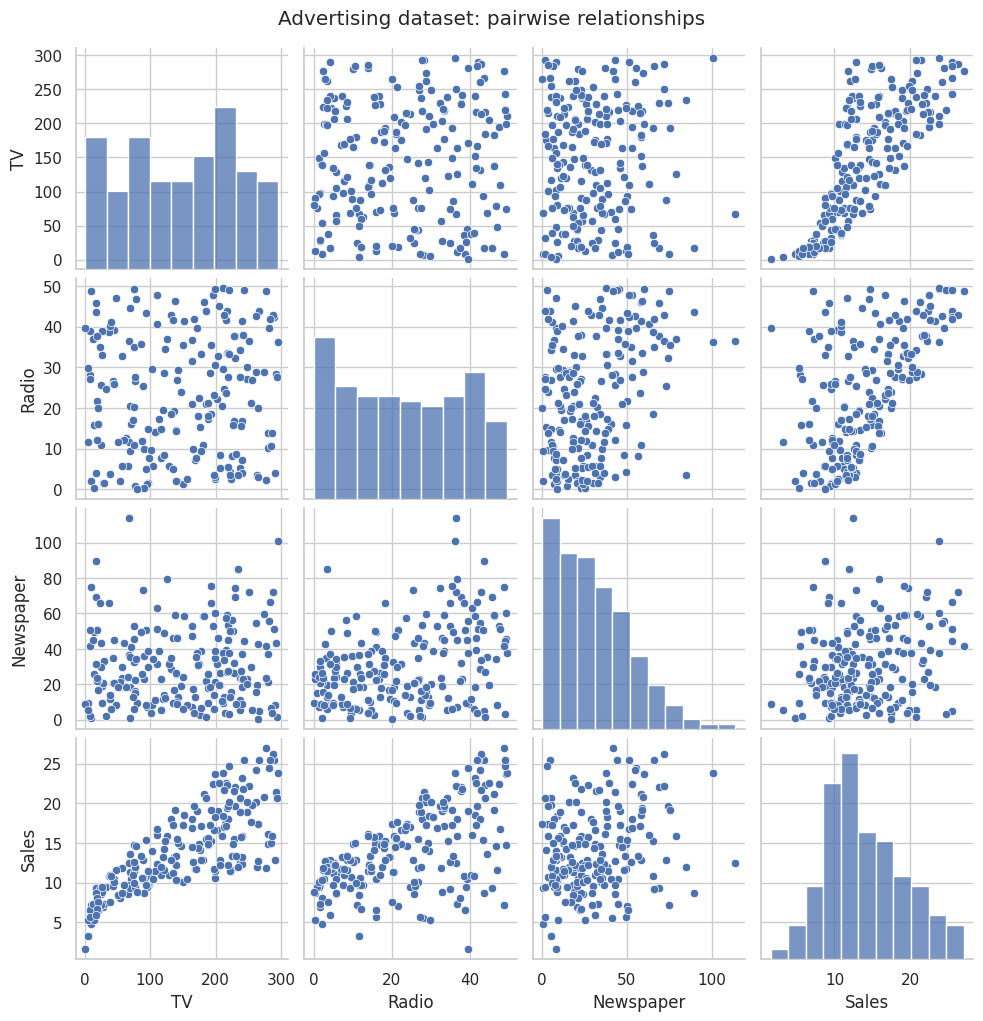

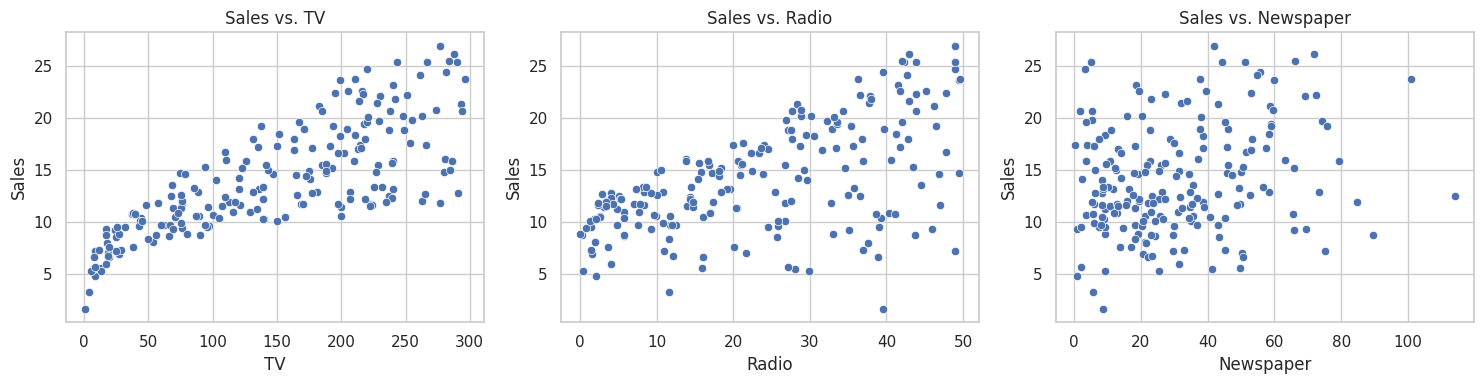

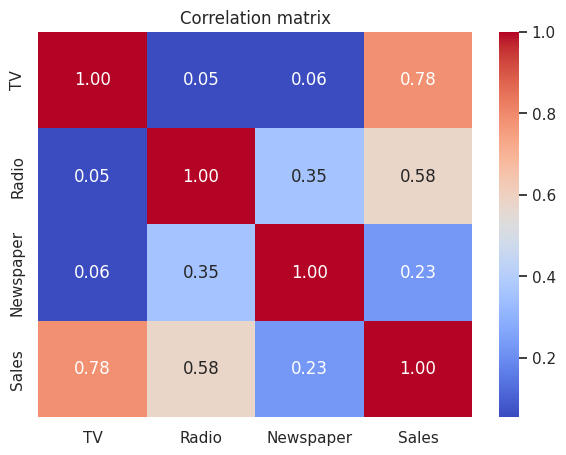

In [11]:
sns.pairplot(df)
plt.suptitle("Advertising dataset: pairwise relationships", y=1.02)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.scatterplot(data=df, x=feature, y="Sales", ax=ax)
    ax.set_title(f"Sales vs. {feature}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

## 3. Prepare the data and train models
The target is `Sales`; the predictors are the three advertising channels. We use an 80/20 split so model evaluation uses rows not used during training.

In [12]:
target = "Sales"
features = ["TV", "Radio", "Newspaper"]
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        "model": model,
        "predictions": pred,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    }

metrics = pd.DataFrame({
    name: {metric: values[metric] for metric in ["MAE", "RMSE", "R2"]}
    for name, values in results.items()
}).T
display(metrics.round(3))

,MAE,RMSE,R2
Linear Regression,1.461,1.782,0.899
Random Forest Regressor,0.629,0.757,0.982


## 4. Residual plot and channel impact

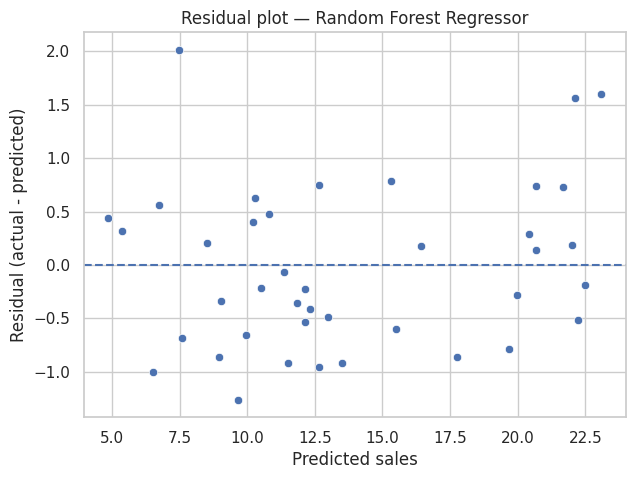

Linear regression coefficients:


,coefficient
Radio,0.189195
TV,0.044730
Newspaper,0.002761


Best model by test R²: Random Forest Regressor
The channel with the largest absolute linear-regression coefficient is: Radio


In [13]:
best_name = metrics["R2"].idxmax()
best_model = results[best_name]["model"]
best_pred = results[best_name]["predictions"]
residuals = y_test - best_pred

plt.figure(figsize=(7, 5))
sns.scatterplot(x=best_pred, y=residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted sales")
plt.ylabel("Residual (actual - predicted)")
plt.title(f"Residual plot — {best_name}")
plt.show()

linear_model = results["Linear Regression"]["model"]
coef = pd.Series(linear_model.coef_, index=features).sort_values(key=abs, ascending=False)
print("Linear regression coefficients:")
display(coef.to_frame("coefficient"))

print(f"Best model by test R²: {best_name}")
print("The channel with the largest absolute linear-regression coefficient is:", coef.abs().idxmax())

## 5. Conclusion
The Sales Prediction Using Python project explored the relationship between advertising expenditure and product sales using machine learning. The dataset included TV, radio, and newspaper advertising budgets, which were used to train and evaluate Linear Regression and Random Forest Regressor models.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). Based on the test results, the Random Forest Regressor achieved the best R² score among the models evaluated.

The Linear Regression coefficients showed that radio advertising had the largest coefficient (0.189195), followed by TV advertising (0.044730) and newspaper advertising (0.002761). This suggests that radio advertising had the strongest positive linear relationship with sales within this model and dataset.

Overall, this project demonstrates how machine learning can help businesses estimate sales and make more informed advertising-budget decisions. However, the results reflect the available dataset and do not prove that advertising spending alone causes changes in sales.